#### Data Visualisations

In this notebook, we aim to conduct data visualisations on geospatial and temporal aspects of the data, such as investigating prices across Singapore, and across time.

# Essentially, this notebook is trying to justify the usefulness of the suite of predictors we collected and why we went through all the trouble to do so, as well as why we want to use these predictors for our model. It is incomplete and I will update once done. Please let me know your thoughts and if the narrative flows well, thanks guys! - Mark Lim

In [54]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import json
from matplotlib import cm, colors
from matplotlib.collections import PolyCollection

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
import contextily as cx



HERE = Path.cwd().resolve()
PROJECT_ROOT = next((p for p in [HERE, *HERE.parents] if (p / 'data' / 'train.csv').exists()), HERE)
if not (PROJECT_ROOT / 'data' / 'train.csv').exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
DATA_PATH = PROJECT_ROOT / 'data' / 'original_dataset' / 'train.csv'
df = pd.read_csv(DATA_PATH)
print(f'Loaded {DATA_PATH}')
print('Shape:', df.shape)
df.head()

Loaded /Users/marklim/Masters/CS5228/CS5228-project-final/final_report/data/original_dataset/train.csv
Shape: (150000, 11)


,RENT_APPROVAL_DATE,TOWN,BLOCK,STREET,FLAT_TYPE,FLAT_MODEL,FLOOR_AREA_SQM,FURNISHED,LEASE_COMMENCE_DATE,FEE,MONTHLY_RENT
0,2021-01,punggol,604a,punggol road,4 room,model a,93.0,yes,2012,0.0,1800
1,2021-01,sengkang,290c,compassvale crescent,5 room,improved,110.0,yes,2001,0.0,2000
2,2021-01,queenstown,5,ghim moh road,3 room,improved,65.0,yes,1976,0.0,2000
3,2021-01,sengkang,436b,fernvale road,4 room,model a,96.0,yes,2010,0.0,1400
4,2021-01,sembawang,467b,admiralty drive,4 room,premium apartment,102.0,yes,2001,0.0,1800


#### Cleaning the train dataset

In [2]:
TARGET = 'MONTHLY_RENT'
work = df.copy()

# Remove exact duplicate rows from the baseline dataset.
work = work.drop_duplicates().reset_index(drop=True)

# Normalize all text fields: trim whitespace, collapse repeated spaces, and lowercase.
text_columns = work.select_dtypes(include=['object', 'string']).columns
for column in text_columns:
    work[column] = (work[column].astype('string').str.strip()
                    .str.replace(r'\s+', ' ', regex=True).str.lower())

# Standardize common street-type spellings and abbreviations.
street_replacements = {
    r'\bavenue\b': 'ave', r'\broad\b': 'rd',
    r'\bstreet\b': 'st', r'\bdrive\b': 'dr',
    r'\bcentral\b': 'ctrl', r'\bplace\b': 'pl',
    r'\bclose\b': 'cl', r'\bcrescent\b': 'cres',
    r'\blane\b': 'ln', r'\blink\b': 'link',
    r'\bparkway\b': 'pkwy', r'\bterrace\b': 'ter',
    r'\bview\b': 'vw', r'\bwalk\b': 'walk',
}
for pattern, replacement in street_replacements.items():
    work['STREET'] = work['STREET'].str.replace(pattern, replacement, regex=True)
work['STREET'] = work['STREET'].str.replace(r'\s+', ' ', regex=True).str.strip()

# Canonicalize known category variants. These mappings make spelling, case, and
# formatting differences resolve to one category before one-hot encoding.
work['FLAT_TYPE'] = work['FLAT_TYPE'].replace({
    '1 room': '1-room', '2 room': '2-room', '3 room': '3-room',
    '4 room': '4-room', '5 room': '5-room',
})
work['FURNISHED'] = work['FURNISHED'].replace({
    'yes': 1, 'y': 1, 'true': 1, '1': 1,
    'no': 0, 'n': 0, 'false': 0, '0': 0,
}).astype('Int64')

work['approval_date'] = pd.to_datetime(work['RENT_APPROVAL_DATE'], format='%Y-%m', errors='coerce')
work['RENT_YEAR'] = work['approval_date'].dt.year
work['RENT_MONTH'] = work['approval_date'].dt.month
work['RENT_QUARTER'] = work['approval_date'].dt.quarter

### Join with HDB data to get geospatial features

In [67]:
hdb_raw = pd.read_csv(PROJECT_ROOT / 'data' / 'sg-hdb-block.csv', dtype={'POSTAL_CODE': 'string'})

STREET_REPLACEMENTS = {r'\bavenue\b':'ave', r'\broad\b':'rd', r'\bstreet\b':'st', r'\bdrive\b':'dr', r'\bcentral\b':'ctrl', r'\bplace\b':'pl', r'\bclose\b':'cl', r'\bcrescent\b':'cres', r'\blane\b':'ln', r'\bparkway\b':'pkwy', r'\bterrace\b':'ter', r'\bview\b':'vw'}
def normalize_text(s):
    return s.astype('string').str.strip().str.lower().str.replace(r'\s+', ' ', regex=True)
def clean_common(frame):
    out = frame.copy()
    for col in out.select_dtypes(include=['object','string']).columns: out[col] = normalize_text(out[col])
    if 'STREET' in out:
        for pattern, replacement in STREET_REPLACEMENTS.items(): out['STREET'] = out['STREET'].str.replace(pattern, replacement, regex=True)
        out['STREET'] = out['STREET'].str.replace(r'\s+', ' ', regex=True).str.strip()
    if 'FLAT_TYPE' in out: out['FLAT_TYPE'] = out['FLAT_TYPE'].replace({'1 room':'1-room','2 room':'2-room','3 room':'3-room','4 room':'4-room','5 room':'5-room'})
    if 'FURNISHED' in out: out['FURNISHED'] = out['FURNISHED'].replace({'yes':1,'y':1,'true':1,'1':1,'no':0,'n':0,'false':0,'0':0}).astype('Int64')
    return out

hdb = clean_common(hdb_raw)
hdb['ADDRESS_KEY'] = hdb['TOWN'] + '|' + hdb['BLOCK'] + '|' + hdb['STREET']
work['ADDRESS_KEY'] = work['TOWN'] + '|' + work['BLOCK'] + '|' + work['STREET']


hdb = hdb.drop_duplicates('ADDRESS_KEY', keep='first')
geo_columns = ['ADDRESS_KEY','POSTAL_CODE','LATITUDE','LONGITUDE','MAX_FLOOR','YEAR_COMPLETED','SUBZONE','PLANNING_AREA','REGION']
work_geo = work.merge(hdb[geo_columns], on='ADDRESS_KEY', how='left', validate='many_to_one')
work_geo['HDB_BLOCK_MATCHED'] = work_geo['LATITUDE'].notna().astype('int8')
work_geo['BUILDING_AGE'] = work_geo['RENT_YEAR'] - pd.to_numeric(work_geo['YEAR_COMPLETED'], errors='coerce')
# train_geo = postcode_geocoder.transform(train_geo)
# train_geo = floor_transformer.transform(train_geo)
print('HDB match rate:', f"{work_geo['HDB_BLOCK_MATCHED'].mean():.2%}")
work_geo.head()

HDB match rate: 100.00%


,RENT_APPROVAL_DATE,TOWN,BLOCK,STREET,FLAT_TYPE,FLAT_MODEL,FLOOR_AREA_SQM,FURNISHED,LEASE_COMMENCE_DATE,FEE,...,POSTAL_CODE,LATITUDE,LONGITUDE,MAX_FLOOR,YEAR_COMPLETED,SUBZONE,PLANNING_AREA,REGION,HDB_BLOCK_MATCHED,BUILDING_AGE
0,2021-01,punggol,604a,punggol rd,4-room,model a,93.0,1,2012,0.0,...,821604,1.404310,103.907413,16,2010,waterway east,punggol,north-east region,1,11
1,2021-01,sengkang,290c,compassvale cres,5-room,improved,110.0,1,2001,0.0,...,543290,1.397018,103.897535,15,2000,sengkang town centre,sengkang,north-east region,1,21
2,2021-01,queenstown,5,ghim moh rd,3-room,improved,65.0,1,1976,0.0,...,270005,1.312693,103.788309,15,1975,ghim moh,queenstown,central region,1,46
3,2021-01,sengkang,436b,fernvale rd,4-room,model a,96.0,1,2010,0.0,...,792436,1.392878,103.876976,21,2008,fernvale,sengkang,north-east region,1,13
4,2021-01,sembawang,467b,admiralty dr,4-room,premium apartment,102.0,1,2001,0.0,...,752467,1.451141,103.813630,16,1999,sembawang north,sembawang,north region,1,22


### Nearest MRT station and bus stop

Distances are calculated as straight-line (geodesic) distances from each HDB block.

In [70]:
from pathlib import Path

from scipy.spatial import cKDTree

mrt = pd.read_csv(PROJECT_ROOT / 'data' / 'sg-mrt-stations.csv')
bus = pd.read_csv(PROJECT_ROOT / 'data' / 'sg-bus-stops.csv')
bus = bus.rename(columns={'Latitude': 'LATITUDE', 'Longitude': 'LONGITUDE'})

def nearest_locations(points, locations, name_column, prefix):
    lat_scale = 111.32
    mean_lat = np.deg2rad(pd.concat([points['LATITUDE'], locations['LATITUDE']]).mean())
    def project(frame):
        return np.column_stack((frame['LONGITUDE'] * np.cos(mean_lat) * lat_scale, frame['LATITUDE'] * lat_scale))
    tree = cKDTree(project(locations))
    distance_km, nearest_index = tree.query(project(points), k=1)
    result = pd.DataFrame(index=points.index)
    result[f'{prefix}_NAME'] = locations.iloc[nearest_index][name_column].to_numpy()
    result[f'{prefix}_DISTANCE_KM'] = distance_km
    return result

transport_features = pd.concat([
    nearest_locations(work_geo, mrt, 'NAME', 'MRT'),
    nearest_locations(work_geo, bus, 'Description', 'BUS_STOP'),
], axis=1)
work_geo_transport = pd.concat([work_geo.reset_index(drop=True), transport_features.reset_index(drop=True)], axis=1)

display(work_geo_transport[['STREET', 'BLOCK', 'MRT_NAME', 'MRT_DISTANCE_KM', 'BUS_STOP_NAME', 'BUS_STOP_DISTANCE_KM']].head())

,STREET,BLOCK,MRT_NAME,MRT_DISTANCE_KM,BUS_STOP_NAME,BUS_STOP_DISTANCE_KM
0,punggol rd,604a,punggol mrt/lrt station,0.557279,Blk 604A,0.037602
1,compassvale cres,290c,sengkang mrt/lrt station,0.635085,Blk 291A,0.170667
2,ghim moh rd,5,buona vista mrt station,0.626593,Blk 3,0.146237
3,fernvale rd,436b,sengkang mrt/lrt station,2.072135,Blk 436A,0.119677
4,admiralty dr,467b,sembawang mrt station,0.763197,Bet Blks 357/359,0.298647


### MRT stations and bus stops within walking-distance thresholds

In [71]:
from scipy.spatial import cKDTree

def projected_coordinates(frame, mean_lat):
    metres_per_degree = 111320
    return np.column_stack((
        frame['LONGITUDE'].to_numpy(dtype=float) * np.cos(mean_lat) * metres_per_degree,
        frame['LATITUDE'].to_numpy(dtype=float) * metres_per_degree,
    ))

mean_lat = np.deg2rad(pd.concat([
    work_geo['LATITUDE'], mrt['LATITUDE'], bus['LATITUDE']
]).mean())
hdb_coordinates = projected_coordinates(work_geo, mean_lat)
mrt_tree = cKDTree(projected_coordinates(mrt, mean_lat))
bus_tree = cKDTree(projected_coordinates(bus, mean_lat))

transport_counts = pd.DataFrame(index=work_geo.index)
for distance_m in (250, 750):
    transport_counts[f'MRT_WITHIN_{distance_m}M'] = [
        len(indices) for indices in mrt_tree.query_ball_point(hdb_coordinates, r=distance_m)
    ]
    transport_counts[f'BUS_STOPS_WITHIN_{distance_m}M'] = [
        len(indices) for indices in bus_tree.query_ball_point(hdb_coordinates, r=distance_m)
    ]

work_geo_transport = pd.concat([
    work_geo_transport.reset_index(drop=True),
    transport_counts.reset_index(drop=True),
], axis=1)

display(work_geo_transport[[
    'STREET', 'BLOCK', 'MRT_WITHIN_250M', 'MRT_WITHIN_750M',
    'BUS_STOPS_WITHIN_250M', 'BUS_STOPS_WITHIN_750M'
]].head())

,STREET,BLOCK,MRT_WITHIN_250M,MRT_WITHIN_750M,BUS_STOPS_WITHIN_250M,BUS_STOPS_WITHIN_750M
0,punggol rd,604a,0,3,4,37
1,compassvale cres,290c,0,2,2,38
2,ghim moh rd,5,0,2,4,29
3,fernvale rd,436b,0,0,5,32
4,admiralty dr,467b,0,0,0,33


### Nearest school

In [72]:
schools = pd.read_csv(PROJECT_ROOT / 'data' / 'sg-schools.csv')

mean_lat = np.deg2rad(pd.concat([
    work_geo['LATITUDE'], schools['LATITUDE']
]).mean())
metres_per_degree = 111320

def project_coordinates(frame):
    return np.column_stack((
        frame['LONGITUDE'].to_numpy(dtype=float) * np.cos(mean_lat) * metres_per_degree,
        frame['LATITUDE'].to_numpy(dtype=float) * metres_per_degree,
    ))

school_tree = cKDTree(project_coordinates(schools))
school_distance_m, school_index = school_tree.query(project_coordinates(work_geo), k=1)

work_geo_transport['NEAREST_SCHOOL'] = schools.iloc[school_index]['NAME'].to_numpy()
work_geo_transport['SCHOOL_DISTANCE_KM'] = school_distance_m / 1000

display(work_geo_transport[[
    'STREET', 'BLOCK', 'NEAREST_SCHOOL', 'SCHOOL_DISTANCE_KM'
]].head())

FEATURES_OUTPUT_PATH = PROJECT_ROOT / 'data' / 'processed' / 'hdb_features_before_accessibility.csv'
work_geo_transport.to_csv(FEATURES_OUTPUT_PATH, index=False)
print(f'Saved {len(work_geo_transport):,} rows and {len(work_geo_transport.columns):,} features to {FEATURES_OUTPUT_PATH}')

,STREET,BLOCK,NEAREST_SCHOOL,SCHOOL_DISTANCE_KM
0,punggol rd,604a,punggol view primary school,0.267819
1,compassvale cres,290c,compassvale secondary school,0.275222
2,ghim moh rd,5,henry park primary school,0.629340
3,fernvale rd,436b,sengkang green primary school,0.195715
4,admiralty dr,467b,canberra secondary school,0.236951


Saved 149,575 rows and 36 features to /Users/marklim/Masters/CS5228/CS5228-proj-ML/data/processed/hdb_features_before_accessibility.csv


### Public-transport accessibility to proxy destinations

### Accessibility score calculation

For each unique HDB coordinate, the notebook requests public-transport travel time to five representative proxy destinations. Travel times are converted from seconds to minutes. The destination-specific columns also retain the number of transfers and walking distance returned by the routing API.

- `mean_travel_time_min`: arithmetic mean travel time across all proxy destinations.
- `median_travel_time_min`: median travel time across all proxy destinations.
- `cbd_travel_time_min`: travel time to Raffles Place.
- `regional_hub_travel_time_min`: shortest travel time to Jurong East or Tampines Regional Centre.
- `essential_services_time_min`: travel time to Singapore General Hospital.
- `education_access_time_min`: travel time to NUS.
- `ACCESSIBILITY_SCORE`: negative mean travel time (`-mean_travel_time_min`), so higher values indicate better accessibility.

A missing travel time indicates that the routing request failed or returned no usable itinerary; aggregate values use the remaining valid destinations.

Note: the below code cell takes several hours to run, so we do not recommend running the below API calls.
Additionally, we understand that it is best practice to keep the API keys in a .env file, however, the API keys have already expired and thus, to run the code, new API keys will have to be taken from OneMAP and LTA

In [ ]:
import sys
import time
from concurrent.futures import ThreadPoolExecutor
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
from scripts.get_distance_to_place import get_travel_time

proxy_locations = {
    'raffles_place': '1.2839,103.8515',       # CBD employment
    'jurong_east': '1.3331,103.7423',         # western regional hub
    'tampines_regional_centre': '1.3530,103.9452',  # eastern regional hub
    'nus': '1.2966,103.7764',                  # education
    'singapore_general_hospital': '1.2793,103.8350', # healthcare
}

# Query each unique coordinate once, then merge results back to all rental rows.
route_points = work_geo_transport[['STREET', 'LATITUDE', 'LONGITUDE']].drop_duplicates(['LATITUDE', 'LONGITUDE']).copy()
route_results = route_points[['LATITUDE', 'LONGITUDE']].copy()
route_points = route_points.rename(columns={
    'STREET': 'street', 'LATITUDE': 'approx_lat', 'LONGITUDE': 'approx_lon'
})

cache_path = PROJECT_ROOT / 'data' / 'processed' / 'accessibility_route_cache.csv'
route_cache = pd.read_csv(cache_path) if cache_path.exists() else pd.DataFrame(columns=['key', 'destination', 'time_seconds', 'transfers', 'walking_distance_m'])
def make_key(lat, lon, destination): return f'{lat:.6f}|{lon:.6f}|{destination}'
def request_route(item):
    row, destination, coordinates, key = item
    try: result = get_travel_time(row, coordinates)
    except Exception: result = {}
    return {'key': key, 'destination': destination, 'time_seconds': result.get('time_taken_by_public_transport', np.nan), 'transfers': result.get('transfers', np.nan), 'walking_distance_m': result.get('walking_distance', np.nan)}

for destination, coordinates in proxy_locations.items():
    keys = [make_key(lat, lon, destination) for lat, lon in zip(route_results['LATITUDE'], route_results['LONGITUDE'])]
    cached = set(route_cache.loc[route_cache['destination'].eq(destination), 'key'])
    missing = [(row, destination, coordinates, key) for (_, row), key in zip(route_points.iterrows(), keys) if key not in cached]
    print(f'{destination}: {len(missing):,} uncached requests')
    for start in range(0, len(missing), 250):
        batch_start = time.monotonic()
        batch = missing[start:start + 250]
        with ThreadPoolExecutor(max_workers=20) as pool: results = list(pool.map(request_route, batch))
        route_cache = pd.concat([route_cache, pd.DataFrame(results)], ignore_index=True).drop_duplicates('key', keep='last')
        route_cache.to_csv(cache_path, index=False)
        if start + 250 < len(missing): time.sleep(max(0, 60 - (time.monotonic() - batch_start)))
    current = route_cache.set_index('key').reindex(keys)
    route_results[f'{destination}_time_min'] = current['time_seconds'].to_numpy() / 60
    route_results[f'{destination}_transfers'] = current['transfers'].to_numpy()
    route_results[f'{destination}_walking_distance_m'] = current['walking_distance_m'].to_numpy()

work_geo_transport = work_geo_transport.merge(route_results, on=['LATITUDE', 'LONGITUDE'], how='left', validate='many_to_one')

time_columns = [f'{destination}_time_min' for destination in proxy_locations]
work_geo_transport['mean_travel_time_min'] = work_geo_transport[time_columns].mean(axis=1)
work_geo_transport['median_travel_time_min'] = work_geo_transport[time_columns].median(axis=1)
work_geo_transport['cbd_travel_time_min'] = work_geo_transport['raffles_place_time_min']
work_geo_transport['regional_hub_travel_time_min'] = work_geo_transport[[
    'jurong_east_time_min', 'tampines_regional_centre_time_min'
]].min(axis=1)
work_geo_transport['essential_services_time_min'] = work_geo_transport['singapore_general_hospital_time_min']
work_geo_transport['education_access_time_min'] = work_geo_transport['nus_time_min']
work_geo_transport['ACCESSIBILITY_SCORE'] = -work_geo_transport['mean_travel_time_min']

display(work_geo_transport[[
    'ADDRESS_KEY', 'mean_travel_time_min', 'median_travel_time_min',
    'cbd_travel_time_min', 'regional_hub_travel_time_min',
    'essential_services_time_min', 'education_access_time_min',
    'ACCESSIBILITY_SCORE'
]].head())

### Positive accessibility score

In [81]:
work_geo_transport_positive_score = work_geo_transport.copy()
work_geo_transport_positive_score['ACCESSIBILITY_SCORE'] = (
    np.exp(-work_geo_transport_positive_score['mean_travel_time_min']/ 30)
)

display(work_geo_transport_positive_score[[
    'mean_travel_time_min', 'ACCESSIBILITY_SCORE'
]].head())


,mean_travel_time_min,ACCESSIBILITY_SCORE
0,40.443333,0.259730
1,37.053333,0.290802
2,17.000000,0.567414
3,45.313333,0.220812
4,52.156667,0.175774


In [ ]:
FEATURES_OUTPUT_PATH = PROJECT_ROOT / 'data' / 'processed' / 'hdb_features_with_accessibility.csv'
work_geo_transport_positive_score.to_csv(FEATURES_OUTPUT_PATH, index=False)
print(f'Saved {len(work_geo_transport_positive_score):,} rows and {len(work_geo_transport_positive_score.columns):,} features to {FEATURES_OUTPUT_PATH}')

Saved 149,575 rows and 58 features to /Users/marklim/Masters/CS5228/CS5228-proj-ML/data/processed/hdb_features_after_accessibility_v2.csv


### Highest and lowest accessibility scores

In [84]:
accessibility_ranking = (
    work_geo_transport_positive_score
    .groupby('TOWN', as_index=False)
    .agg(ACCESSIBILITY_SCORE=('ACCESSIBILITY_SCORE', 'mean'),
         MEAN_TRAVEL_TIME_MIN=('mean_travel_time_min', 'mean'))
)

top_5_accessibility = accessibility_ranking.nlargest(5, 'ACCESSIBILITY_SCORE')
bottom_5_accessibility = accessibility_ranking.nsmallest(5, 'ACCESSIBILITY_SCORE')

print('Top 5 towns by accessibility score')
display(top_5_accessibility)

print('Bottom 5 towns by accessibility score')
display(bottom_5_accessibility)

Top 5 towns by accessibility score


,TOWN,ACCESSIBILITY_SCORE,MEAN_TRAVEL_TIME_MIN
9,clementi,0.561361,18.817933
7,central,0.547205,19.454581
4,bukit merah,0.529017,20.102856
18,queenstown,0.528949,20.243396
6,bukit timah,0.467683,23.647956


Bottom 5 towns by accessibility score


,TOWN,ACCESSIBILITY_SCORE,MEAN_TRAVEL_TIME_MIN
25,yishun,0.317151,37.884846
24,woodlands,0.318302,38.304406
16,pasir ris,0.319807,36.942180
19,sembawang,0.329019,37.179313
17,punggol,0.343585,35.434090


## Data Visualisation 

After collecting a few extra features, we can start some visualizations

In [71]:
from scipy.spatial import cKDTree

df_PATH = PROJECT_ROOT  /'data' / 'original_dataset' / 'auxiliary'/ 'hdb_features_with_accessibility.csv'
df = pd.read_csv(df_PATH)

df['MONTHLY_RENT'] = pd.to_numeric(df['MONTHLY_RENT'], errors='coerce')
df = df.dropna(subset=['MONTHLY_RENT'])

# Join shopping-mall locations and count malls near each HDB record.
malls = pd.read_csv(PROJECT_ROOT / 'data' / 'original_dataset' / 'auxiliary' / 'sg-shopping-malls.csv')
def project_lat_lon(lat, lon, lat0=1.35):
    earth_radius = 6371000.0
    x = np.radians(np.asarray(lon, dtype=float)) * np.cos(np.radians(lat0)) * earth_radius
    y = np.radians(np.asarray(lat, dtype=float)) * earth_radius
    return np.column_stack([x, y])

hdb_locations = project_lat_lon(df['LATITUDE'], df['LONGITUDE'])
mall_locations = project_lat_lon(malls['LATITUDE'], malls['LONGITUDE'])
mall_tree = cKDTree(mall_locations)
for distance_m in (250, 750):
    df[f'MALLS_WITHIN_{distance_m}M'] = [
        len(indices) for indices in mall_tree.query_ball_point(hdb_locations, r=distance_m)
    ]

display(df[['TOWN', 'SUBZONE', 'MALLS_WITHIN_250M', 'MALLS_WITHIN_750M']].head())

GEOJSON_PATH_SUBZONES = PROJECT_ROOT  /'data' / 'original_dataset' / 'auxiliary'/ 'MasterPlan2019SubzoneBoundaryNoSeaGEOJSON.geojson'
with GEOJSON_PATH_SUBZONES.open(encoding='utf-8') as f:
    subzones = json.load(f)['features']

GEOJSON_PATH_TOWNS = PROJECT_ROOT  /'data' / 'original_dataset' / 'auxiliary'/ 'MasterPlan2019PlanningAreaBoundaryNoSea.geojson'
with GEOJSON_PATH_TOWNS.open(encoding='utf-8') as f:
    towns = json.load(f)['features']


df['approval_date'] = pd.to_datetime(df['approval_date'])

,TOWN,SUBZONE,MALLS_WITHIN_250M,MALLS_WITHIN_750M
0,punggol,waterway east,0,2
1,sengkang,sengkang town centre,0,1
2,queenstown,ghim moh,0,3
3,sengkang,fernvale,1,1
4,sembawang,sembawang north,0,1


In [72]:
df.columns

Index(['RENT_APPROVAL_DATE', 'TOWN', 'BLOCK', 'STREET', 'FLAT_TYPE',
       'FLAT_MODEL', 'FLOOR_AREA_SQM', 'FURNISHED', 'LEASE_COMMENCE_DATE',
       'FEE', 'MONTHLY_RENT', 'approval_date', 'RENT_YEAR', 'RENT_MONTH',
       'RENT_QUARTER', 'ADDRESS_KEY', 'POSTAL_CODE', 'LATITUDE', 'LONGITUDE',
       'MAX_FLOOR', 'YEAR_COMPLETED', 'SUBZONE', 'PLANNING_AREA', 'REGION',
       'HDB_BLOCK_MATCHED', 'BUILDING_AGE', 'MRT_NAME', 'MRT_DISTANCE_KM',
       'BUS_STOP_NAME', 'BUS_STOP_DISTANCE_KM', 'MRT_WITHIN_250M',
       'BUS_STOPS_WITHIN_250M', 'MRT_WITHIN_750M', 'BUS_STOPS_WITHIN_750M',
       'NEAREST_SCHOOL', 'SCHOOL_DISTANCE_KM', 'raffles_place_time_min',
       'raffles_place_transfers', 'raffles_place_walking_distance_m',
       'jurong_east_time_min', 'jurong_east_transfers',
       'jurong_east_walking_distance_m', 'tampines_regional_centre_time_min',
       'tampines_regional_centre_transfers',
       'tampines_regional_centre_walking_distance_m', 'nus_time_min',
       'nus_transf

### Rentals Across Time

We want to observe if rental prices have changed drastically over the time period of our dataset. If so, we may have to take only a certain slice of the data, probably the more recent periods, to train our model on.

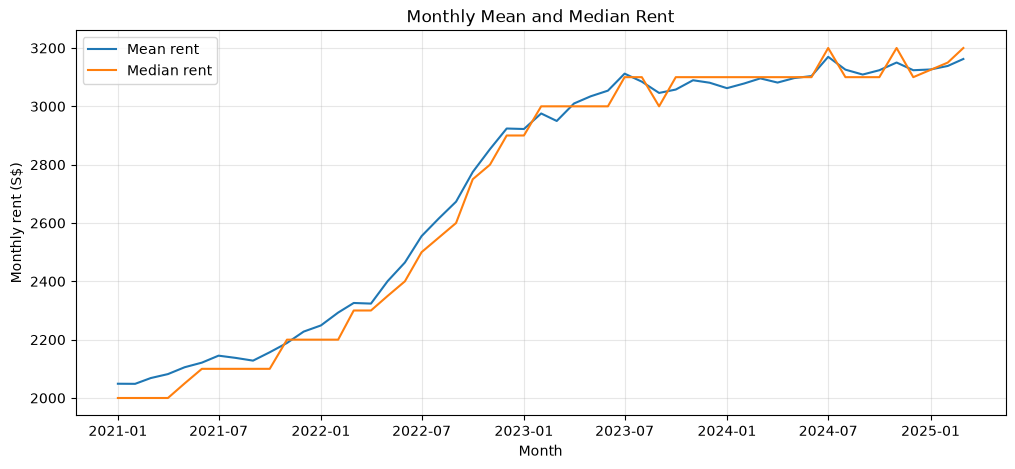

In [40]:
monthly_summary = (
    df.groupby("approval_date")["MONTHLY_RENT"]
      .agg(["mean", "median", "count"])
      .asfreq("MS")
)

fig, ax1 = plt.subplots(figsize=(12, 5))

ax1.plot(
    monthly_summary.index,
    monthly_summary["mean"],
    label="Mean rent"
)

ax1.plot(
    monthly_summary.index,
    monthly_summary["median"],
    label="Median rent"
)

ax1.set_xlabel("Month")
ax1.set_ylabel("Monthly rent (S$)")
ax1.set_title("Monthly Mean and Median Rent")
ax1.legend()
ax1.grid(alpha=0.3)

plt.show()

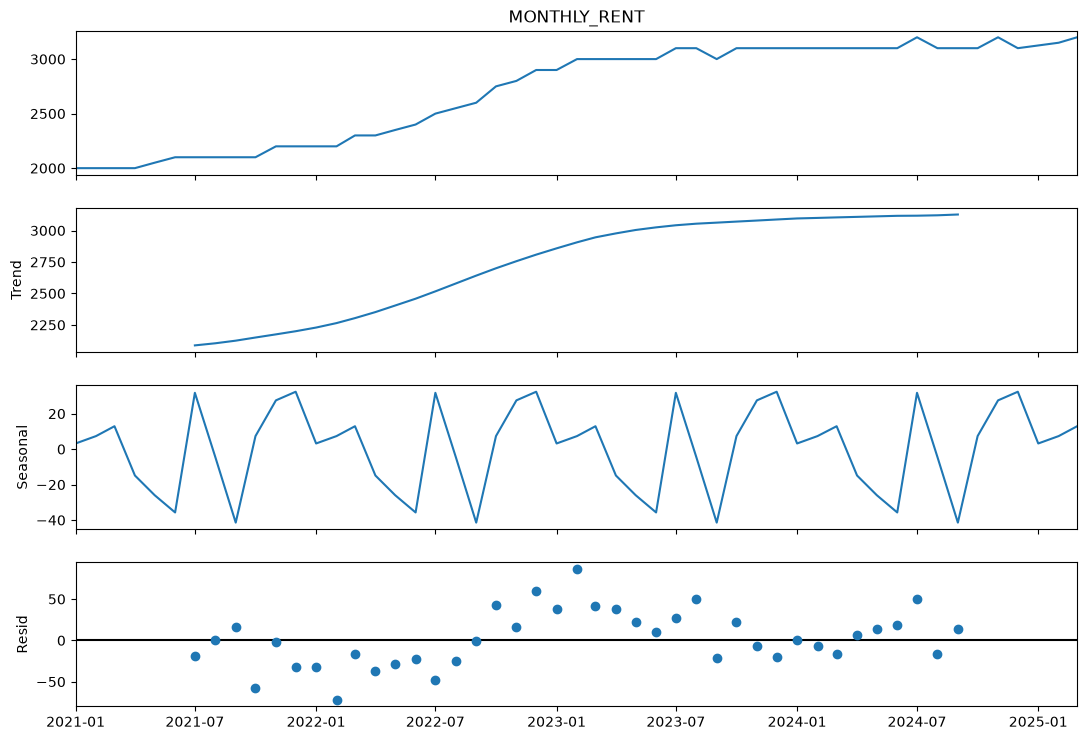

In [44]:
from statsmodels.tsa.seasonal import seasonal_decompose

monthly_rent = (
    df.groupby("approval_date")["MONTHLY_RENT"]
    .median()
    .sort_index()
    .asfreq("MS")
)
decomposition = seasonal_decompose(
    monthly_rent,
    model="additive",
    period=12
)

decomposition.plot()
plt.gcf().set_size_inches(12, 8)
plt.show()

#### Observations 

We do observe that median rent has been heating up from 2021 up to the the beginning of 2023, before stabilising in the middle of 2023. Additionally, we do note there is some form of seasonality in the data. It might be wise to either use data from 2023 onwards to train the data, or to account for this seasonality somewhere in our model.

## Basic Data Visualisations
Intuitively, one of the most important determining factors when it comes to rental prices is the location of the house as well as the type of house. 
Given we know that the rental prices have increased over the years, we want to ensure that the relativity of both location and house types hold. For example, a house in the downtown area that fetched a higher rent than a house in the suburbs in 2021 should still fetch a higher rent in 2025. 

Baseline year: 2021


,spearman_like_rank_correlation
YEAR,
2021,1.000000
2022,0.827199
2023,0.736043
2024,0.872964
2025,0.884896


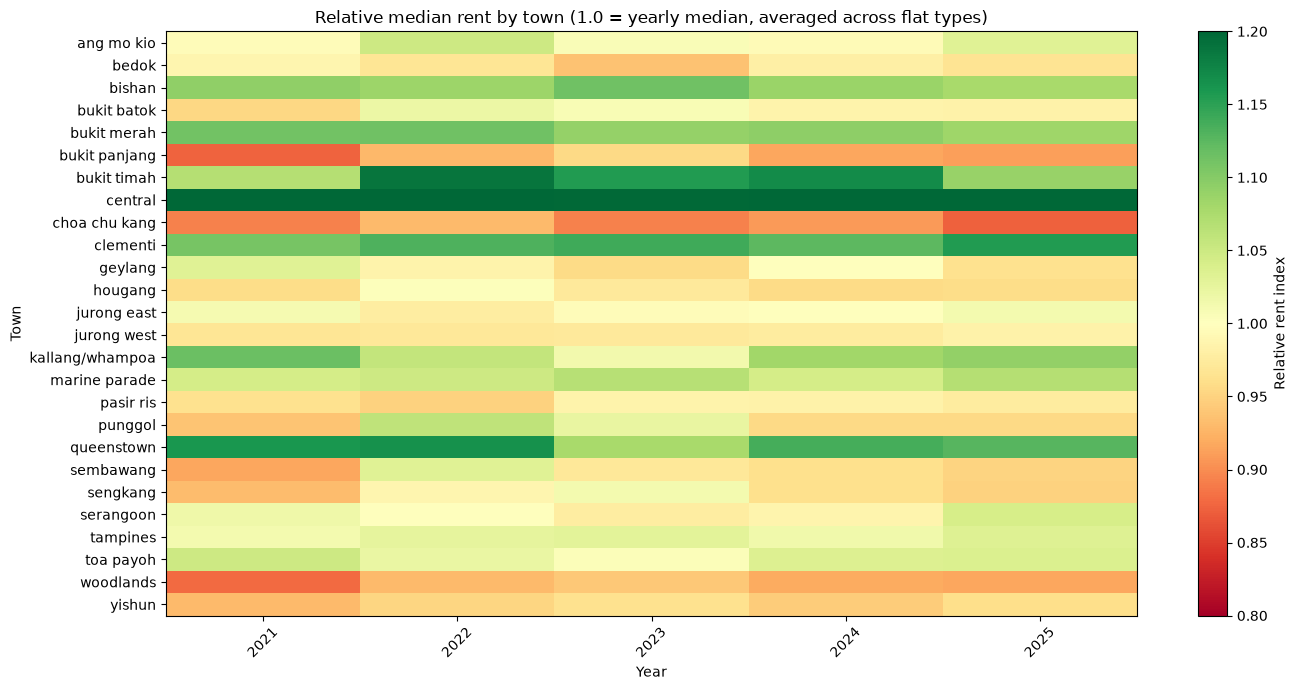

In [45]:
# Check whether town rent rankings remain relatively stable across years, within flat type.
rent_check = df.copy()
rent_check['YEAR'] = pd.to_datetime(rent_check['RENT_APPROVAL_DATE'], errors='coerce').dt.year
rent_check['MONTHLY_RENT'] = pd.to_numeric(rent_check['MONTHLY_RENT'], errors='coerce')
rent_check = rent_check.dropna(subset=['YEAR', 'TOWN', 'FLAT_TYPE', 'MONTHLY_RENT'])

town_year = (rent_check.groupby(['YEAR', 'FLAT_TYPE', 'TOWN'])['MONTHLY_RENT']
             .median().rename('median_rent').reset_index())
town_year['town_rank'] = (town_year.groupby(['YEAR', 'FLAT_TYPE'])['median_rent']
                          .rank(ascending=False, method='average'))

years = sorted(town_year['YEAR'].unique())
baseline_year = years[0]
baseline = town_year[town_year['YEAR'] == baseline_year]
rank_check = town_year.merge(
    baseline[['FLAT_TYPE', 'TOWN', 'town_rank']],
    on=['FLAT_TYPE', 'TOWN'], suffixes=('', '_baseline')
)
rank_check['rank_change'] = rank_check['town_rank'] - rank_check['town_rank_baseline']

stability = (rank_check.groupby('YEAR')
            .apply(lambda g: g[['town_rank', 'town_rank_baseline']].corr().iloc[0, 1],
                   include_groups=False)
            .rename('spearman_like_rank_correlation'))
print(f'Baseline year: {baseline_year}')
display(stability.to_frame())

relative_index = (town_year.assign(
    market_median=town_year.groupby(['YEAR', 'FLAT_TYPE'])['median_rent'].transform('median')
)).assign(relative_rent_index=lambda x: x['median_rent'] / x['market_median'])

fig, ax = plt.subplots(figsize=(14, 7))
heatmap_data = (relative_index.groupby(['YEAR', 'TOWN'])['relative_rent_index']
                .mean().unstack('TOWN'))
im = ax.imshow(heatmap_data.T, aspect='auto', cmap='RdYlGn', vmin=0.8, vmax=1.2)
ax.set_xticks(range(len(heatmap_data.index)), heatmap_data.index.astype(int), rotation=45)
ax.set_yticks(range(len(heatmap_data.columns)), heatmap_data.columns)
ax.set_xlabel('Year')
ax.set_ylabel('Town')
ax.set_title('Relative median rent by town (1.0 = yearly median, averaged across flat types)')
fig.colorbar(im, ax=ax, label='Relative rent index')
plt.tight_layout()
plt.show()


Flat-type baseline year: 2021


,spearman_rank_correlation
YEAR,
2021,1.0
2022,1.0
2023,1.0
2024,1.0
2025,1.0


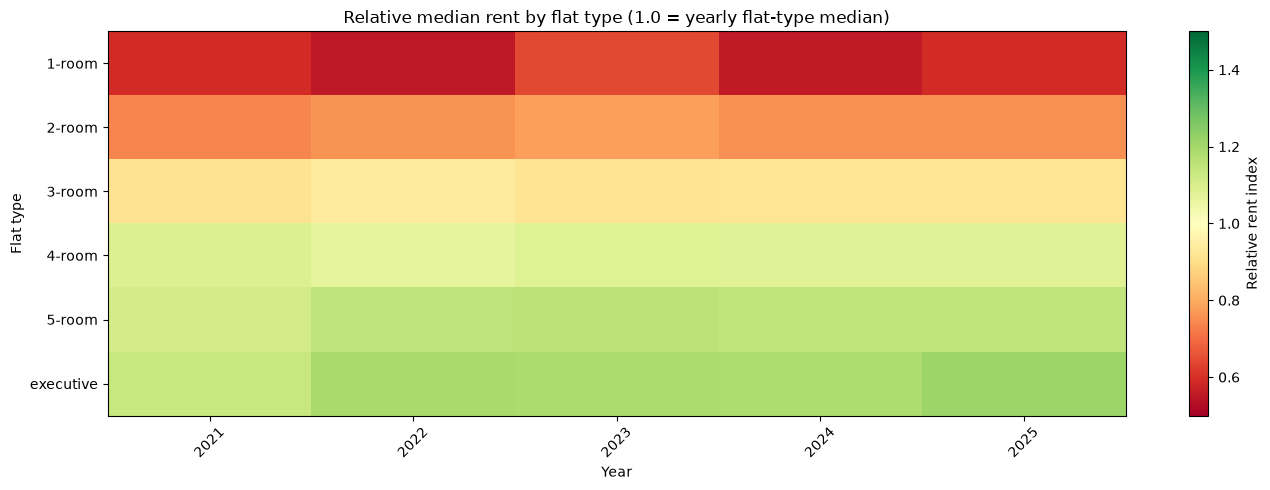

In [48]:
# Check whether flat-type rent rankings remain relatively stable across years.
flat_year = (rent_check.groupby(['YEAR', 'FLAT_TYPE'])['MONTHLY_RENT']
             .median().rename('median_rent').reset_index())
flat_year['flat_type_rank'] = (flat_year.groupby('YEAR')['median_rent']
                              .rank(ascending=False, method='average'))

flat_baseline = flat_year[flat_year['YEAR'] == baseline_year]
flat_rank_check = flat_year.merge(
    flat_baseline[['FLAT_TYPE', 'flat_type_rank']],
    on='FLAT_TYPE', suffixes=('', '_baseline')
)
flat_rank_check['rank_change'] = (
    flat_rank_check['flat_type_rank'] - flat_rank_check['flat_type_rank_baseline']
)

flat_rank_stability = (flat_rank_check.groupby('YEAR')
    .apply(lambda g: g['flat_type_rank'].corr(
        g['flat_type_rank_baseline'], method='spearman'))
    .rename('spearman_rank_correlation'))
print(f'Flat-type baseline year: {baseline_year}')
display(flat_rank_stability.to_frame())

flat_relative_index = (flat_year.assign(
    market_median=flat_year.groupby('YEAR')['median_rent'].transform('median')
)).assign(relative_rent_index=lambda x: x['median_rent'] / x['market_median'])

flat_heatmap = flat_relative_index.pivot(
    index='FLAT_TYPE', columns='YEAR', values='relative_rent_index'
)
fig, ax = plt.subplots(figsize=(14, 5))
im = ax.imshow(flat_heatmap, aspect='auto', cmap='RdYlGn', vmin=0.5, vmax=1.5)
ax.set_xticks(range(len(flat_heatmap.columns)), flat_heatmap.columns.astype(int), rotation=45)
ax.set_yticks(range(len(flat_heatmap.index)), flat_heatmap.index)
ax.set_xlabel('Year')
ax.set_ylabel('Flat type')
ax.set_title('Relative median rent by flat type (1.0 = yearly flat-type median)')
fig.colorbar(im, ax=ax, label='Relative rent index')
plt.tight_layout()
plt.show()


#### Observations 

Over the years, both relative pricing across room types and towns have held relatively stable

For towns, we see slight changes in rank, especially in 2023. For example, we can see that in 2021, Sengkang and Woodlands were relatively low on the rent index, but climbed up the ranks over the years in 2023, before going back down in rankings again. 

Overall, it would be safe to make an assumption that relative pricing holds, and we can use the entire dataset for data visualisation and exploration without having to treat different years seperately. 

#### Breakdown by Area and House types

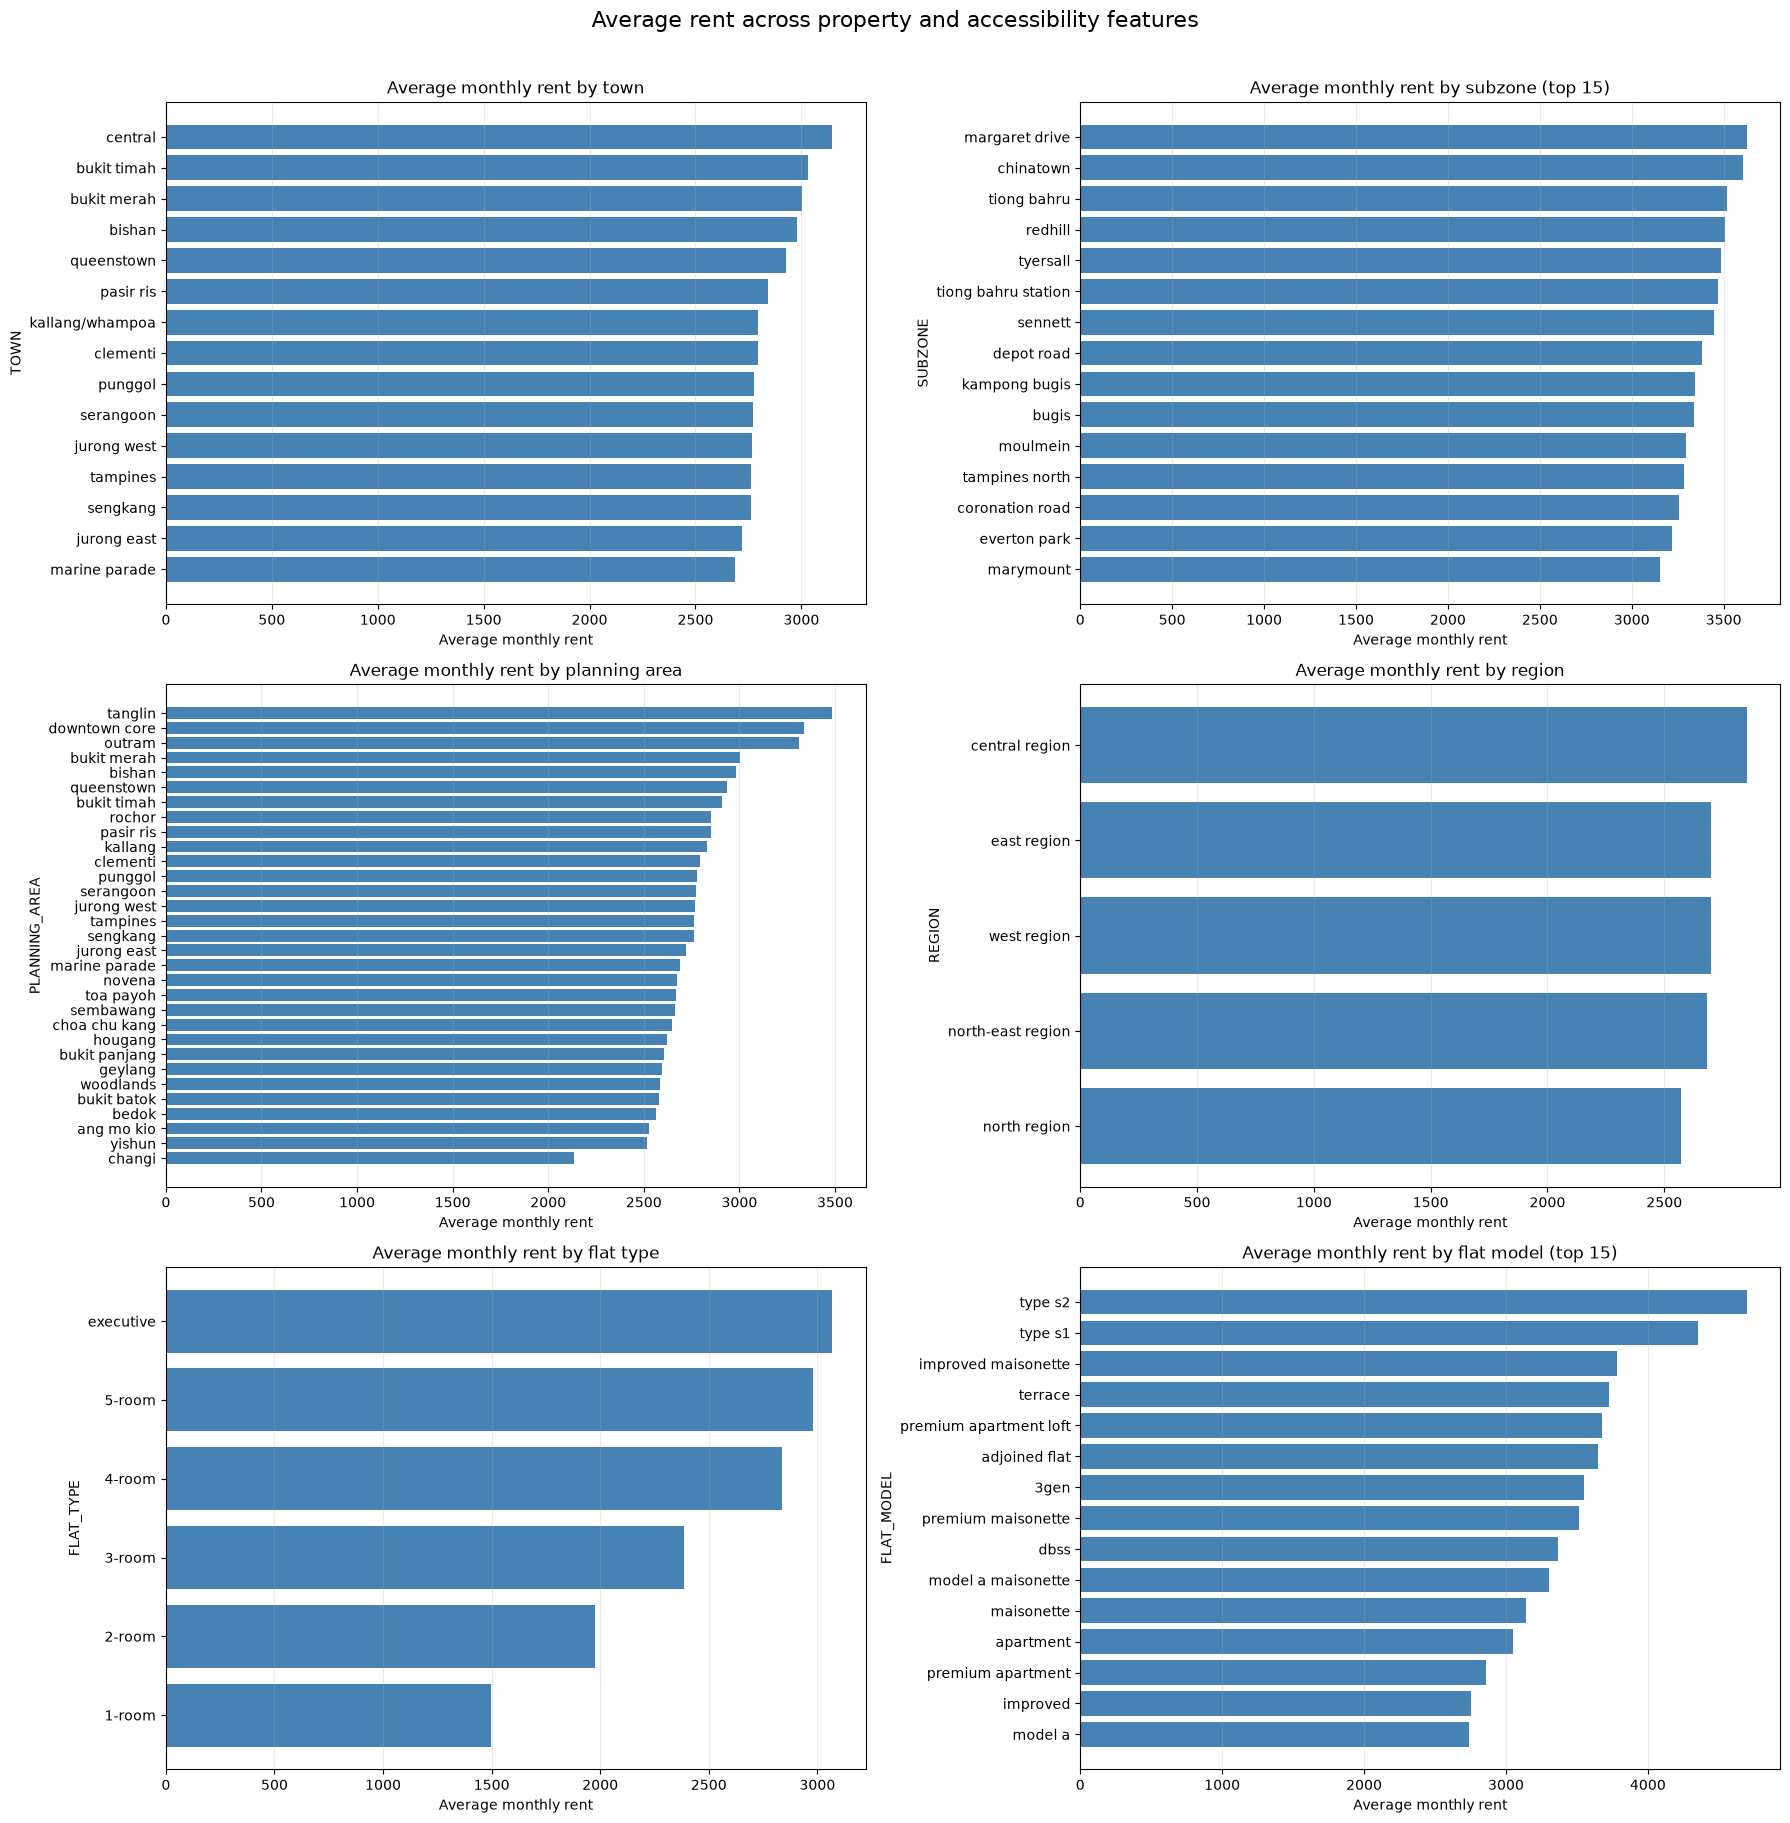

In [ ]:
group_columns = ['TOWN', 'SUBZONE', 'PLANNING_AREA', 'REGION', 'FLAT_TYPE', 'FLAT_MODEL']
missing = [c for c in group_columns if c not in df.columns]
if missing:
    raise KeyError(f'Missing columns required for grouped rent analysis: {missing}')

def average_rent_by(column):
    return (df.groupby(column, dropna=False).agg(
        average_rent=('MONTHLY_RENT', 'mean'),
        median_rent=('MONTHLY_RENT', 'median'),
        observations=('MONTHLY_RENT', 'size')
    ).sort_values('average_rent', ascending=False))

town_rent = average_rent_by('TOWN')
subzone_rent = average_rent_by('SUBZONE')
planning_area_rent = average_rent_by('PLANNING_AREA')
region_rent = average_rent_by('REGION')
flat_type_rent = average_rent_by('FLAT_TYPE')
flat_model_rent = average_rent_by('FLAT_MODEL')


fig, axes = plt.subplots(3, 2, figsize=(18, 18))
plot_specs = [
    ('TOWN', town_rent, 'Average monthly rent by town', 15),
    ('SUBZONE', subzone_rent, 'Average monthly rent by subzone (top 15)', 15),
    ('PLANNING_AREA', planning_area_rent, 'Average monthly rent by planning area', None),
    ('REGION', region_rent, 'Average monthly rent by region', None),
    ('FLAT_TYPE', flat_type_rent, 'Average monthly rent by flat type', None),
    ('FLAT_MODEL', flat_model_rent, 'Average monthly rent by flat model (top 15)', 15)
]
for ax, (column, table, title, top_n) in zip(axes.flat, plot_specs):
    plot_table = table.head(top_n) if top_n else table
    plot_table = plot_table.sort_values('average_rent')
    ax.barh(plot_table.index.astype(str), plot_table['average_rent'], color='steelblue')
    ax.set_title(title)
    ax.set_xlabel('Average monthly rent')
    ax.set_ylabel(column)
    ax.grid(axis='x', alpha=0.25)
fig.suptitle('Average rent across property and accessibility features', fontsize=16, y=1.01)
plt.tight_layout()
plt.show()

### Rental price heat map by planning subzone

The map uses the median `MONTHLY_RENT` of geocoded HDB rental records within each subzone.
We bring in a GeoJSON file provided by the Urban Land Authority to help with our visualizations
We want to investigate what are the defining characteristics of a house's location would be useful in predicting rent

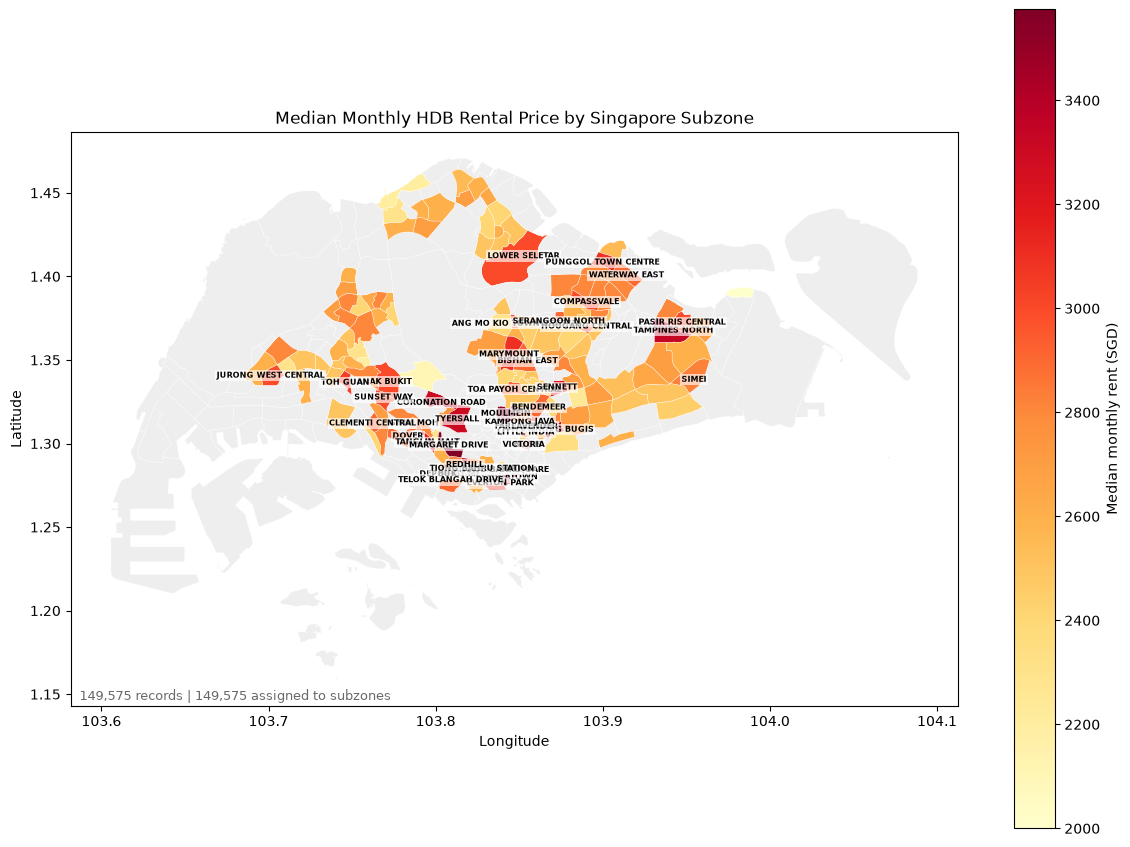

In [62]:
def polygon_parts(geometry):
    # Return the exterior ring for Polygon and MultiPolygon geometries.
    if geometry['type'] == 'Polygon':
        return [geometry['coordinates'][0]]
    return [polygon[0] for polygon in geometry['coordinates']]

# work_geo already contains the HDB block's authoritative SUBZONE. Using it
# avoids an expensive point-in-polygon calculation for every rental row.
rent_points = df[['SUBZONE', 'MONTHLY_RENT']].rename(columns={'SUBZONE': 'SUBZONE_N'}).copy()
rent_points['SUBZONE_N'] = rent_points['SUBZONE_N'].astype('string').str.strip().str.upper()
rent_points['MONTHLY_RENT'] = pd.to_numeric(rent_points['MONTHLY_RENT'], errors='coerce')
rent_by_subzone = (rent_points.dropna(subset=['SUBZONE_N', 'MONTHLY_RENT'])
                    .groupby('SUBZONE_N')['MONTHLY_RENT']
                    .agg(median_rent='median', rental_records='size')
                    .reset_index())
rent_lookup = rent_by_subzone.set_index('SUBZONE_N')['median_rent'].to_dict()

polygons, values = [], []
for feature in subzones:
    name = feature['properties']['SUBZONE_N']
    for ring in polygon_parts(feature['geometry']):
        polygons.append(ring)
        values.append(rent_lookup.get(name, float('nan')))

valid_rents = rent_by_subzone['median_rent']
norm = colors.Normalize(vmin=valid_rents.min(), vmax=valid_rents.max())
cmap = plt.colormaps.get_cmap('YlOrRd').copy()
cmap.set_bad('#eeeeee')
fig, ax = plt.subplots(figsize=(12, 12))
collection = PolyCollection(polygons, array=np.asarray(values, dtype=float), cmap=cmap, norm=norm, edgecolor='white', linewidth=0.25)
ax.add_collection(collection)
ax.autoscale()
ax.set_aspect('equal')
ax.set_xlabel('Longitude')
ax.set_ylabel('Latitude')
ax.set_title('Median Monthly HDB Rental Price by Singapore Subzone')
for feature in subzones:
    name = feature['properties']['SUBZONE_N']
    rent = rent_lookup.get(name)
    if rent is not None and rent > 2800:
        rings = polygon_parts(feature['geometry'])
        points = [point for ring in rings for point in ring]
        centroid_lon = np.mean([point[0] for point in points])
        centroid_lat = np.mean([point[1] for point in points])
        ax.text(centroid_lon, centroid_lat, name, ha='center', va='center', fontsize=6, fontweight='bold', color='black', bbox=dict(facecolor='white', edgecolor='none', alpha=0.65, pad=1))
fig.colorbar(collection, ax=ax, label='Median monthly rent (SGD)', shrink=0.7)
ax.text(0.01, 0.01, f'{len(rent_points):,} records | {rent_points["SUBZONE_N"].notna().sum():,} assigned to subzones', transform=ax.transAxes, fontsize=9, color='dimgray')
plt.tight_layout()
plt.show()

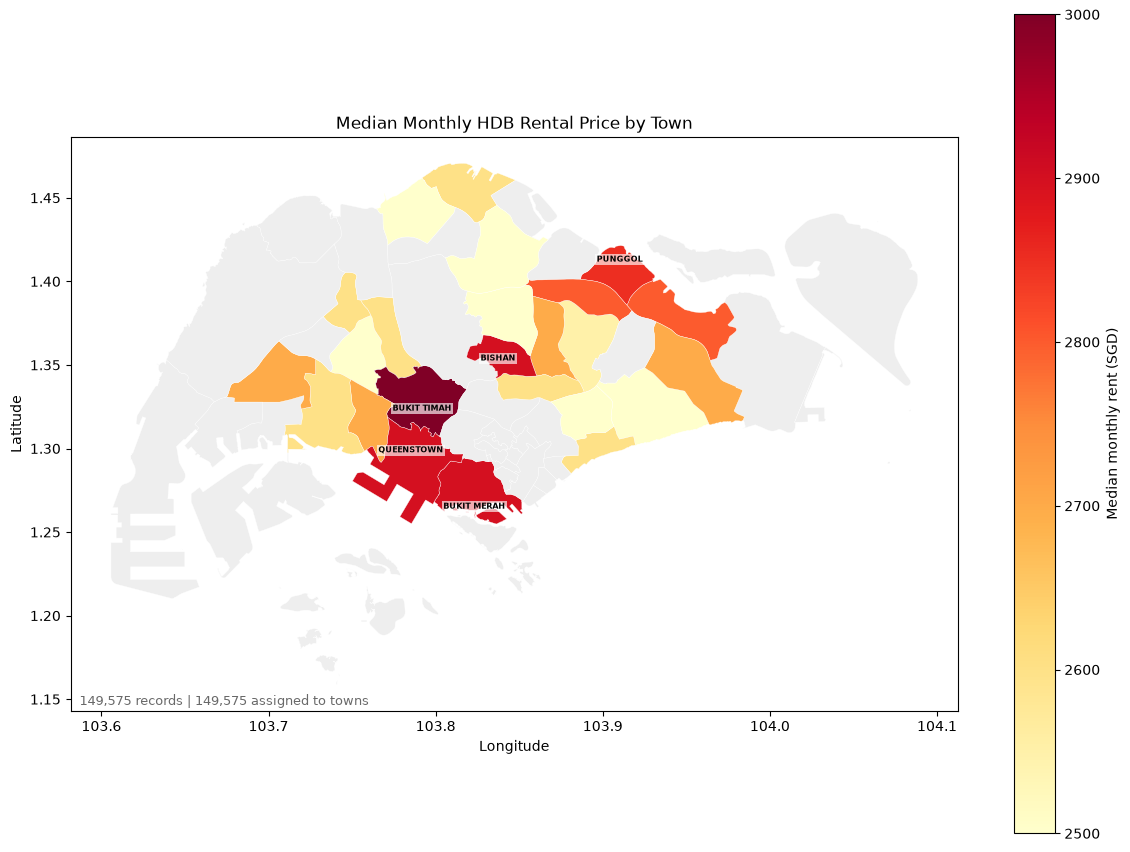

In [51]:
# Median monthly HDB rental price by town using planning-area boundaries.
PLANNING_AREA_GEOJSON_PATH = PROJECT_ROOT / 'data' / 'original_dataset' / 'auxiliary' / 'MasterPlan2019PlanningAreaBoundaryNoSea.geojson'
with PLANNING_AREA_GEOJSON_PATH.open(encoding='utf-8') as f:
    planning_areas = json.load(f)['features']

rent_points = df[['TOWN', 'MONTHLY_RENT']].rename(columns={'TOWN': 'TOWN_N'}).copy()
rent_points['TOWN_N'] = rent_points['TOWN_N'].astype('string').str.strip().str.upper()
rent_points['MONTHLY_RENT'] = pd.to_numeric(rent_points['MONTHLY_RENT'], errors='coerce')
rent_by_town = (rent_points.dropna(subset=['TOWN_N', 'MONTHLY_RENT'])
                 .groupby('TOWN_N')['MONTHLY_RENT']
                 .agg(median_rent='median', rental_records='size')
                 .reset_index())
rent_lookup = rent_by_town.set_index('TOWN_N')['median_rent'].to_dict()

polygons, values = [], []
for feature in planning_areas:
    name = feature['properties']['PLN_AREA_N']
    for ring in polygon_parts(feature['geometry']):
        polygons.append(ring)
        values.append(rent_lookup.get(name, float('nan')))

valid_rents = rent_by_town['median_rent']
norm = colors.Normalize(vmin=valid_rents.min(), vmax=valid_rents.max())
cmap = plt.colormaps.get_cmap('YlOrRd').copy()
cmap.set_bad('#eeeeee')
fig, ax = plt.subplots(figsize=(12, 12))
collection = PolyCollection(polygons, array=np.asarray(values, dtype=float), cmap=cmap, norm=norm, edgecolor='white', linewidth=0.25)
ax.add_collection(collection)
ax.autoscale()
ax.set_aspect('equal')
ax.set_xlabel('Longitude')
ax.set_ylabel('Latitude')
ax.set_title('Median Monthly HDB Rental Price by Town')
for feature in planning_areas:
    name = feature['properties']['PLN_AREA_N']
    rent = rent_lookup.get(name)
    if rent is not None and rent > 2800:
        rings = polygon_parts(feature['geometry'])
        points = [point for ring in rings for point in ring]
        centroid_lon = np.mean([point[0] for point in points])
        centroid_lat = np.mean([point[1] for point in points])
        ax.text(centroid_lon, centroid_lat, name, ha='center', va='center', fontsize=6, fontweight='bold', color='black', bbox=dict(facecolor='white', edgecolor='none', alpha=0.65, pad=1))
fig.colorbar(collection, ax=ax, label='Median monthly rent (SGD)', shrink=0.7)
ax.text(0.01, 0.01, f'{len(rent_points):,} records | {rent_points["TOWN_N"].notna().sum():,} assigned to towns', transform=ax.transAxes, fontsize=9, color='dimgray')
plt.tight_layout()
plt.show()


#### Observations 

1. Median monthly rent is higher in areas that are close to the Downtown of Singapore. Areas such as Margaret Drive, Tyersall and Telok Blangah, which are nearer to downtown core show high rents. 
2. However, we also see high rents in areas such as Tampines North and Jurong West Central that are not near the downtown core, as well as Lower Seletar. We can do further investigation into why this could be the case

#### Concentration of housing types across towns. 

Looking at the various housing types across towns could give us insight as to why different areas fetch different rentals. This could help explain why certain areas, even though further from the downtown core, have a high rent.

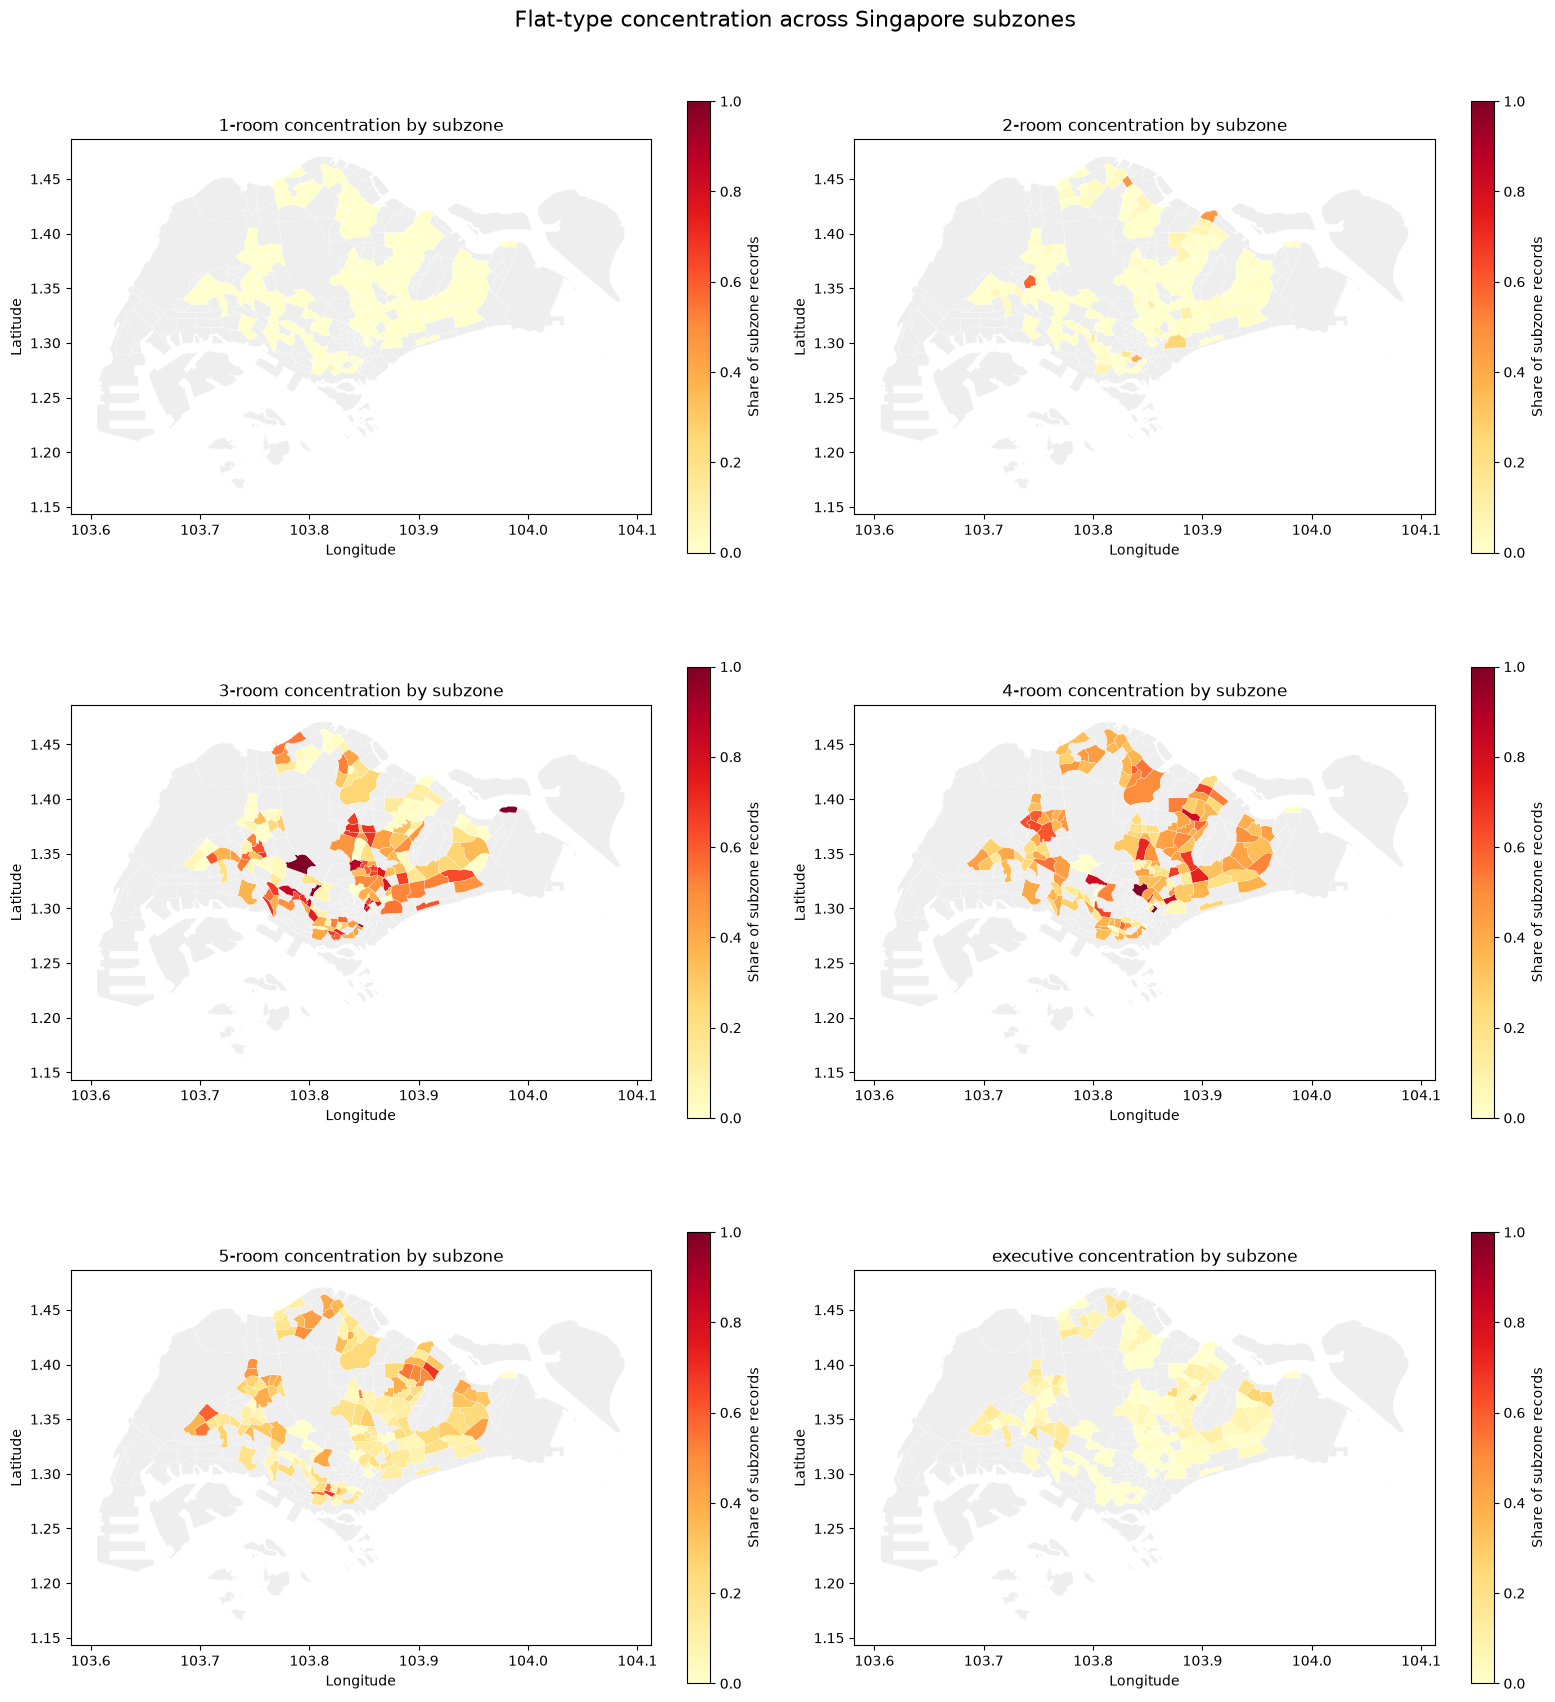

In [52]:
# Plot the concentration of each flat type across Singapore subzones.
SUBZONE_GEOJSON_PATH = PROJECT_ROOT / 'data' / 'original_dataset' / 'auxiliary' / 'MasterPlan2019SubzoneBoundaryNoSeaGEOJSON.geojson'
with SUBZONE_GEOJSON_PATH.open(encoding='utf-8') as f:
    subzone_features = json.load(f)['features']

flat_points = df[['SUBZONE', 'FLAT_TYPE']].copy()
flat_points['SUBZONE_N'] = flat_points['SUBZONE'].astype('string').str.strip().str.upper()
flat_points['FLAT_TYPE'] = flat_points['FLAT_TYPE'].astype('string').str.strip()
flat_points = flat_points.dropna(subset=['SUBZONE_N', 'FLAT_TYPE'])

flat_counts = pd.crosstab(flat_points['SUBZONE_N'], flat_points['FLAT_TYPE'])
flat_shares = flat_counts.div(flat_counts.sum(axis=1), axis=0)
flat_types = sorted(flat_shares.columns.tolist())

ncols = 2
nrows = int(np.ceil(len(flat_types) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(16, 6 * nrows), squeeze=False)
norm = colors.Normalize(vmin=0, vmax=1)
cmap = plt.colormaps.get_cmap('YlOrRd').copy()
cmap.set_bad('#eeeeee')

for ax, flat_type in zip(axes.flat, flat_types):
    polygons, values = [], []
    for feature in subzone_features:
        name = feature['properties']['SUBZONE_N']
        value = flat_shares[flat_type].get(name, float('nan'))
        for ring in polygon_parts(feature['geometry']):
            polygons.append(ring)
            values.append(value)

    collection = PolyCollection(polygons, array=np.asarray(values, dtype=float), cmap=cmap, norm=norm, edgecolor='white', linewidth=0.2)
    ax.add_collection(collection)
    ax.autoscale()
    ax.set_aspect('equal')
    ax.set_title(f'{flat_type} concentration by subzone')
    ax.set_xlabel('Longitude')
    ax.set_ylabel('Latitude')
    fig.colorbar(collection, ax=ax, label='Share of subzone records', shrink=0.75)

for ax in axes.flat[len(flat_types):]:
    ax.axis('off')

fig.suptitle('Flat-type concentration across Singapore subzones', fontsize=16)
plt.tight_layout()
plt.show()


#### Observations 

We do see that areas we identified earlier such as Tampines North, Punggol and Jurong West have a higher concentratino of 5-room and executive flats. 
These could be an indication that these living spaces are more conducive and we should look beyond just simple location coordinates to try to help us predict rental prices

## Conduciveness of Living Spaces 

To judge how conducive a living space is, some of the things we can look at is accessibility and nearby amenities. 

### Accessibility

First we take a look at accessibility, which can be evaluated using number of bus stops and MRT stations in each subzone as well as how well an area is connected to the rest of the island. 

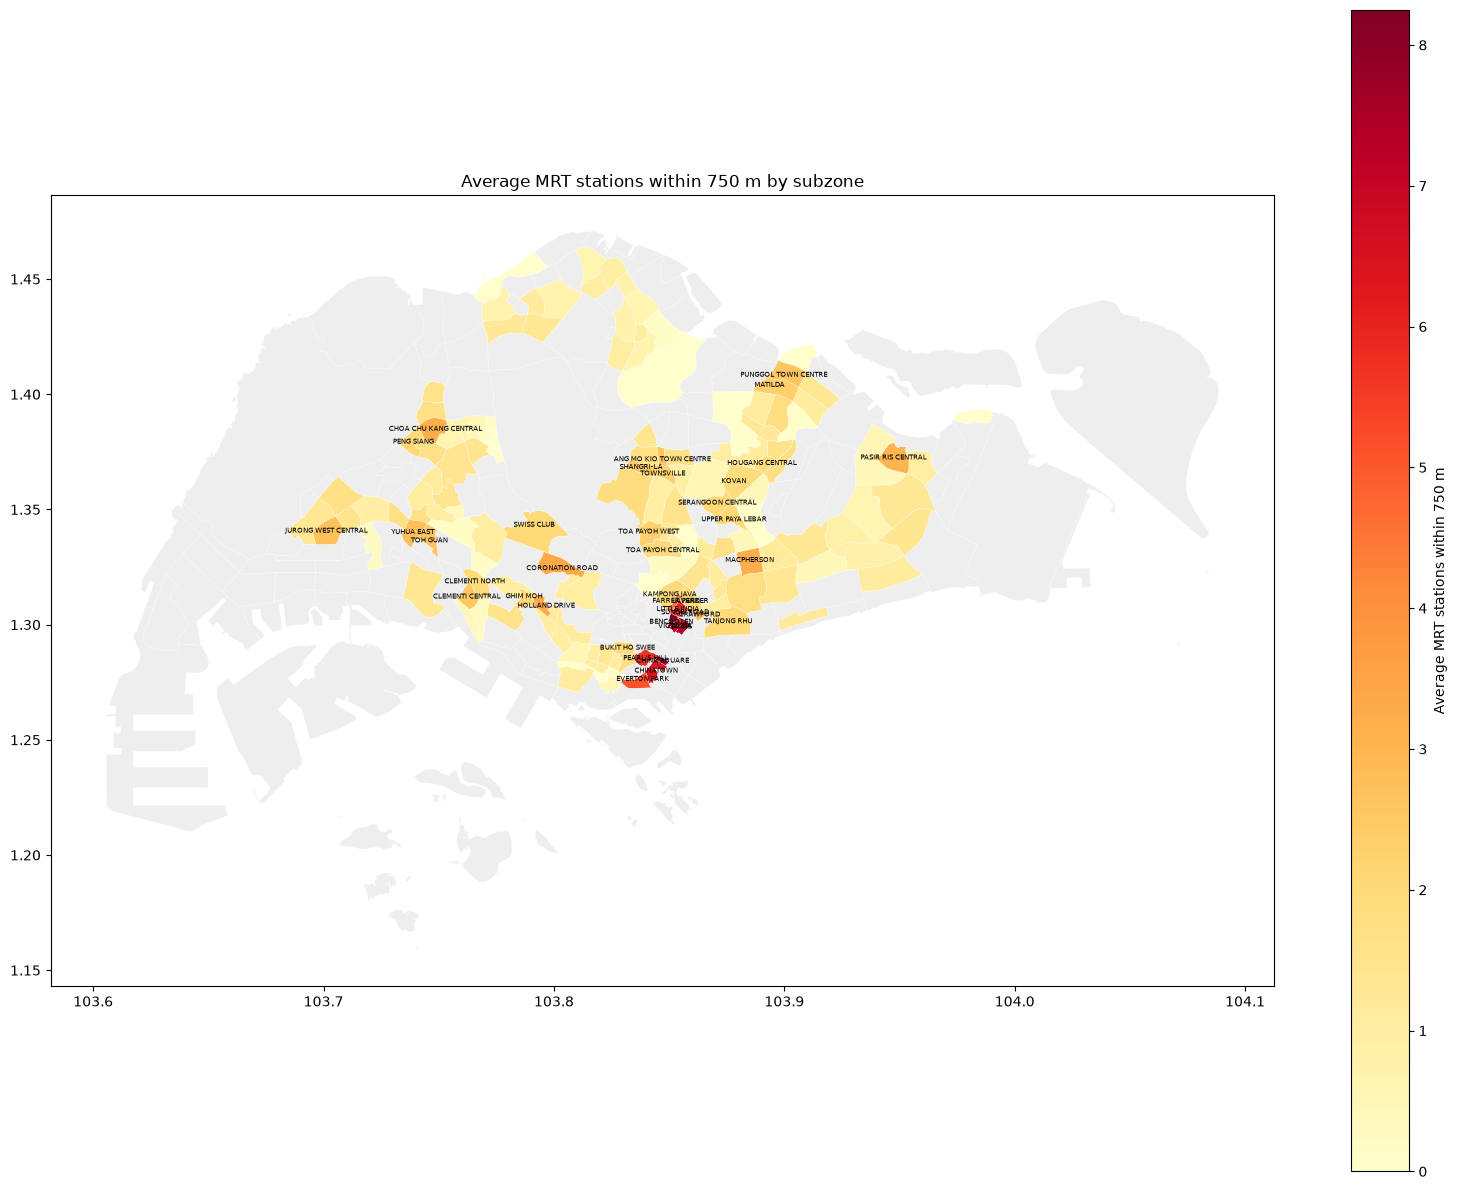

In [68]:
# MRT station density across subzones.
transport_data = df.copy()
transport_data['SUBZONE_N'] = transport_data['SUBZONE'].astype('string').str.strip().str.upper()
transport_data['MRT_WITHIN_750M'] = pd.to_numeric(transport_data['MRT_WITHIN_750M'], errors='coerce')
mrt_summary = transport_data.dropna(subset=['SUBZONE_N']).groupby('SUBZONE_N')['MRT_WITHIN_750M'].mean()
norm = colors.Normalize(vmin=0, vmax=mrt_summary.max())
cmap = plt.colormaps.get_cmap('YlOrRd').copy()
cmap.set_bad('#eeeeee')
polygons, values = [], []
fig, ax = plt.subplots(figsize=(16, 12))
for feature in subzone_features:
    name = feature['properties']['SUBZONE_N']
    points = [point for ring in polygon_parts(feature['geometry']) for point in ring]
    for ring in polygon_parts(feature['geometry']):
        polygons.append(ring)
        values.append(mrt_summary.get(name, float('nan')))
    if mrt_summary.get(name, float('nan')) >= mrt_summary.quantile(0.75):
        ax.text(np.mean([p[0] for p in points]), np.mean([p[1] for p in points]), name, fontsize=5, ha='center', va='center')
collection = PolyCollection(polygons, array=np.asarray(values, dtype=float), cmap=cmap, norm=norm, edgecolor='white', linewidth=0.2)
ax.add_collection(collection)
ax.autoscale(); ax.set_aspect('equal')
ax.set_title('Average MRT stations within 750 m by subzone')
fig.colorbar(collection, ax=ax, label='Average MRT stations within 750 m')
plt.tight_layout(); plt.show()


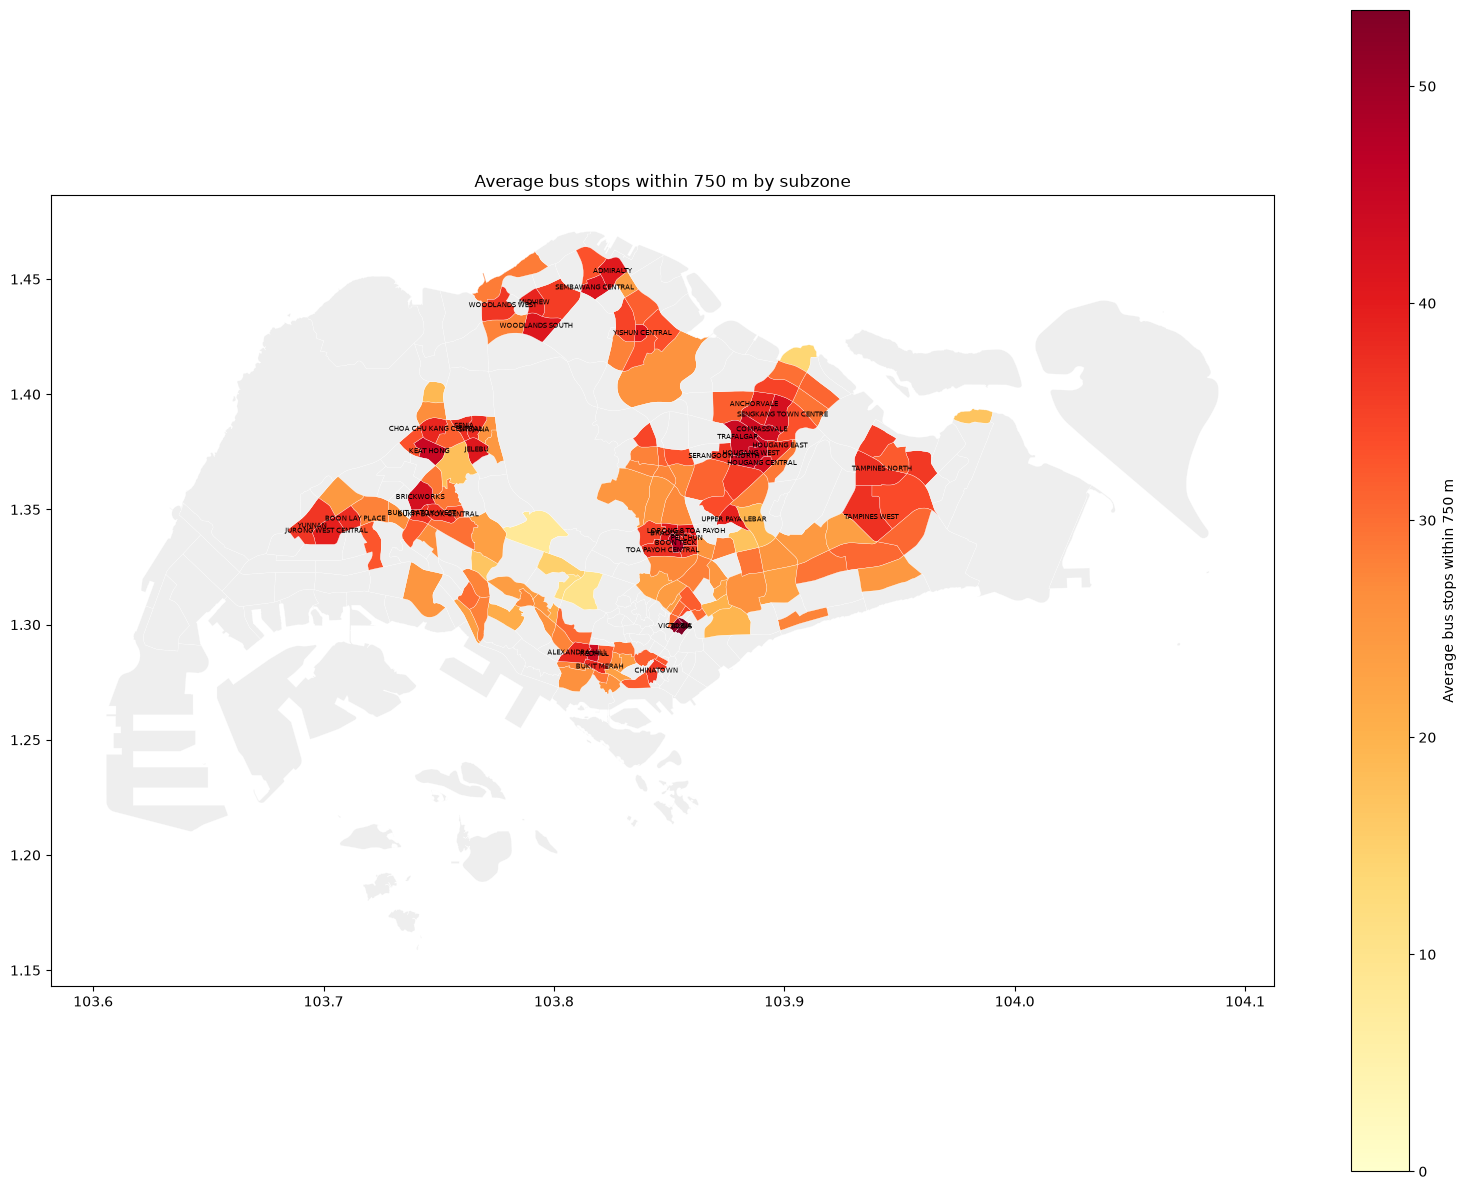

In [69]:
# Bus-stop density across subzones.
transport_data['BUS_STOPS_WITHIN_750M'] = pd.to_numeric(transport_data['BUS_STOPS_WITHIN_750M'], errors='coerce')
bus_summary = transport_data.dropna(subset=['SUBZONE_N']).groupby('SUBZONE_N')['BUS_STOPS_WITHIN_750M'].mean()
norm = colors.Normalize(vmin=0, vmax=bus_summary.max())
polygons, values = [], []
fig, ax = plt.subplots(figsize=(16, 12))
for feature in subzone_features:
    name = feature['properties']['SUBZONE_N']
    points = [point for ring in polygon_parts(feature['geometry']) for point in ring]
    for ring in polygon_parts(feature['geometry']):
        polygons.append(ring)
        values.append(bus_summary.get(name, float('nan')))
    if bus_summary.get(name, float('nan')) >= bus_summary.quantile(0.75):
        ax.text(np.mean([p[0] for p in points]), np.mean([p[1] for p in points]), name, fontsize=5, ha='center', va='center')
collection = PolyCollection(polygons, array=np.asarray(values, dtype=float), cmap=cmap, norm=norm, edgecolor='white', linewidth=0.2)
ax.add_collection(collection)
ax.autoscale(); ax.set_aspect('equal')
ax.set_title('Average bus stops within 750 m by subzone')
fig.colorbar(collection, ax=ax, label='Average bus stops within 750 m')
plt.tight_layout(); plt.show()


### Amenities (Schools , Shopping Malls)

to be completed

### Macro data

to be completed